# Load the same RSML and Ariadne NX

# Load the code to read and transform RSA to networkx trees

In [1]:
from pathlib import Path
from pprint import pprint
from openalea.widgets.mtg import plot as plot_mtg
from openalea import rsml
%run read.py

## Load the data

Each file represent the 2D+t root topology of 5 arabidopsis plants

In [47]:
from pathlib import Path
from pprint import pprint

data = Path('data')/'RSML_03_2026'/'261301MB04'
rsa_files = list(data.glob('61_graph_expertized.rsml'))
pprint(rsa_files)

[PosixPath('data/RSML_03_2026/261301MB04/61_graph_expertized.rsml')]


In [48]:
fn = rsa_files[0]
g = convert_fine_mtg(fn)
# Split the forest into 5 independent graphs
g1, g2, g3, g4, g5 = gs =  split(g)


In [49]:
# Plot one RSA
times_ = times(g1)
plot_mtg(g1)

In [50]:
# Convert all the graphs into NetworkX DAG
dgs = [convert_nx(g) for g in gs]
dg1, dg2, dg3, dg4, dg5 = dgs

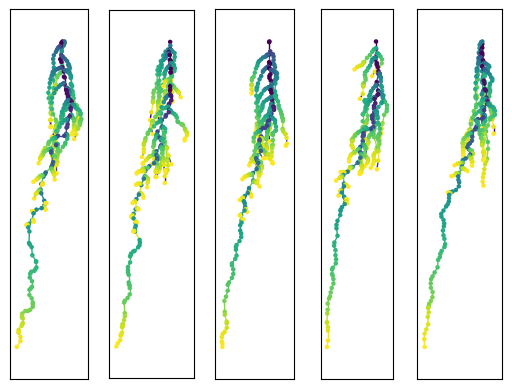

In [51]:
fig, axes = plt.subplots(1,5)
for i in range(5):
    plot_mpl(dgs[i], ax=axes[i])

------------------

## Load data from Ariadne

In [52]:
%run read.py
data2 = Path('data')/'RSML_NX_Root'
rsa_files = list(data2.glob('20262101*_Boite*04*.json'))
rsa_files.sort()
pprint(rsa_files)


[PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantA_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantB_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantC_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantD_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantE_day22.json')]


In [53]:
# Convert all the graphs into NetworkX DAG
nxgs = [json2nx(fn) for fn in rsa_files]

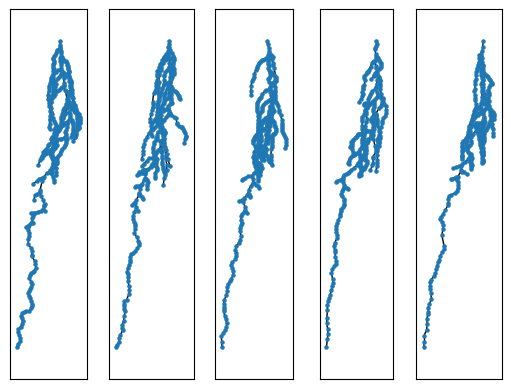

In [54]:
fig, axes = plt.subplots(1,5)
for i in range(5):
    plot_mpl(nxgs[i], ax=axes[i])

In [64]:
gt=nxgs[0]
print(gt[1])

{2: {}}


## Compare RSML (dgs) and Ariadne (nxgs)

In [55]:
g00, g01 = dgs[1], nxgs[1]

In [56]:
r0,_,_=analyze_with_ariadne_graph(g00)
r1,_,_=analyze_with_ariadne_graph(g01)

[(0.0, [10641.430486442314, 10641.430486442314]), (0.01, [2522.575556956652, 10660.072346513629]), (0.02, [2260.6366346340515, 10674.172481025511]), (0.03, [2115.729005792935, 10686.334718712369]), (0.04, [2044.21501832078, 10700.886135058985])]
[(0.0, [35571.854558811836, 35571.854558811836]), (0.01, [9693.179355270911, 35630.874313887194]), (0.02, [8728.508045084678, 35682.546139466685]), (0.03, [8155.852991888842, 35741.111636324196]), (0.04, [7753.422033123243, 35779.76436811458])]


In [57]:
names = list(r0)
for name in names:
    try:
        diff = r0[name]-r1[name]
        if abs(diff) >0.1:
            print(f'Error in {name}:\n R0:{r0[name]}, R1:{r1[name]}')
            print(f'Ratio : {r1[name]/r0[name]}')
    except: pass

Error in Total root length:
 R0:3291.6221799093905, R1:12596.90029788079
Ratio : 3.8269581408117586
Error in Travel distance:
 R0:11679.151993670022, R1:39006.710775663574
Ratio : 3.339858133262141
Error in Total root length (random):
 R0:5394.617237326197, R1:17983.10787545095
Ratio : 3.3335280492234047
Error in Travel distance (random):
 R0:27352.940511779132, R1:90050.64578802431
Ratio : 3.2921742270906984
Error in PR length:
 R0:950.6223705047213, R1:3845.8848286696502
Ratio : 4.045649406112466
Error in PR_minimal_length:
 R0:879.41173519575, R1:3550.9611374950305
Ratio : 4.037882365425355
Error in Branched Zone length:
 R0:0, R1:2121.382626125257
Error in Apical Zone length:
 R0:0, R1:1724.502202544394
Error in Mean LR lengths:
 R0:83.60713605016682, R1:364.6256445504644
Ratio : 4.361178504328602
Error in Mean LR minimal lengths:
 R0:77.70792303217277, R1:344.05130048814607
Ratio : 4.42749319584441
Error in Median LR lengths:
 R0:59.535345884886226, R1:321.5727963528534
Ratio : 5.